# Product Recommendation & Market Basket Analysis

**Business question:** which products do FreshCart customers buy together, and how can those patterns raise average order value through placement, bundles and cross-selling?

**Data:** one year (2025) of point-of-sale line items from three stores of FreshCart, a fictional grocery chain. The dataset is synthetic (see `scripts/generate_data.py`) but deliberately messy, so cleaning is part of the work.

**Method:**
1. Load and audit the raw line items
2. Clean them (cancellations, returns, duplicates, test rows, inconsistent names)
3. Explore baskets, products, categories and timing
4. Build a basket × product matrix and run **Apriori** (mlxtend) to find frequent itemsets
5. Derive **association rules** and rank them by lift, confidence and support
6. Cross-check pair metrics against the SQL implementation in `sql/03_product_analysis.sql`
7. Turn the strongest rules into recommendations

| Metric | Definition | Reads as |
|---|---|---|
| Support(A→B) | P(A and B) | share of all baskets containing both |
| Confidence(A→B) | P(B \| A) | of baskets with A, the share that also have B |
| Lift(A→B) | P(B \| A) / P(B) | how many times likelier B is when A is in the basket; 1 = independent |
| Leverage | P(A,B) − P(A)P(B) | extra co-occurrence above chance, in share of baskets |
| Conviction | (1 − P(B)) / (1 − conf) | how much the rule would be wrong if A and B were independent |

In [1]:
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, OUT, FIG = ROOT / "data", ROOT / "outputs", ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"primary": "#0F766E", "accent": "#E76F51", "muted": "#94A3B8"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "axes.titlesize": 13})

Matplotlib is building the font cache; this may take a moment.


## 1. Load and audit the raw data

In [2]:
raw = pd.read_csv(DATA / "raw" / "transactions_raw.csv", dtype={"customer_id": "string"})
products = pd.read_csv(DATA / "products.csv")
print(f"{len(raw):,} raw line items · {raw['invoice_no'].nunique():,} invoices · {len(products)} products in master")
raw.head()

38,652 raw line items · 8,060 invoices · 40 products in master


,invoice_no,invoice_datetime,customer_id,store_id,product_id,product_name,category,quantity,unit_price
0,INV103510,2025-01-01 09:35,C01855,S02-Riverside,P012,Avocados,Produce,1,1.99
1,INV103510,2025-01-01 09:35,C01855,S02-Riverside,P033,Dark Chocolate,Snacks,2,2.49
2,INV103510,2025-01-01 09:35,C01855,S02-Riverside,P010,Flour Tortillas,Bakery,1,2.29
3,INV103510,2025-01-01 09:35,C01855,S02-Riverside,P027,Orange Juice,Beverages,2,3.49
4,INV103510,2025-01-01 09:35,C01855,S02-Riverside,P018,Spaghetti,Pantry,1,1.59


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 38652 entries, 0 to 38651
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   invoice_no        38652 non-null  str    
 1   invoice_datetime  38652 non-null  str    
 2   customer_id       34178 non-null  string 
 3   store_id          38652 non-null  str    
 4   product_id        38652 non-null  str    
 5   product_name      38461 non-null  str    
 6   category          38652 non-null  str    
 7   quantity          38652 non-null  int64  
 8   unit_price        38652 non-null  float64
dtypes: float64(1), int64(1), str(6), string(1)
memory usage: 2.7 MB


In [4]:
audit = pd.Series({
    "cancelled invoice lines (invoice_no starts with C)": raw["invoice_no"].str.startswith("C").sum(),
    "returns (quantity <= 0, not cancelled)": ((raw["quantity"] <= 0) & ~raw["invoice_no"].str.startswith("C")).sum(),
    "zero-price POS test rows": (raw["unit_price"] == 0).sum(),
    "missing product_name": raw["product_name"].isna().sum(),
    "product_name not matching master": (raw["product_name"].notna()
        & ~raw["product_name"].isin(products["product_name"])).sum(),
    "exact duplicate rows": raw.duplicated().sum(),
    "guest checkouts (invoices without customer_id)": raw.loc[raw["customer_id"].isna(), "invoice_no"].nunique(),
}, name="rows").to_frame()
audit

,rows
cancelled invoice lines (invoice_no starts with C),274
"returns (quantity <= 0, not cancelled)",120
zero-price POS test rows,15
missing product_name,191
product_name not matching master,1147
exact duplicate rows,379
guest checkouts (invoices without customer_id),935


In [5]:
# what the inconsistent names look like
raw.loc[raw["product_name"].notna() & ~raw["product_name"].isin(products["product_name"]), "product_name"] \
   .drop_duplicates().head(8).map(repr).to_list()

["'SOURDOUGH BREAD'",
 "'LEMONS'",
 "'FLOUR TORTILLAS'",
 "'STRAWBERRIES'",
 "'SALMON FILLET'",
 "'  Whole Milk '",
 "'  Croissants '",
 "'CRAFT BEER 6-PACK'"]

## 2. Clean

The same rules are applied in SQL by the `transactions` view in `sql/01_schema_and_cleaning.sql`, so both paths analyse identical data.

1. Drop cancelled invoices and return lines: a return is not a purchase decision.
2. Drop zero-price test rows.
3. Drop exact duplicate rows (scanner double-reads).
4. Replace `product_name` and `category` with the product master's values, keyed on `product_id`. This fixes casing, stray whitespace and missing names in one step.
5. Parse timestamps and compute line totals.

In [6]:
clean = (
    raw[~raw["invoice_no"].str.startswith("C") & (raw["quantity"] > 0) & (raw["unit_price"] > 0)]
    .drop_duplicates()
    .drop(columns=["product_name", "category"])
    .merge(products[["product_id", "product_name", "category"]], on="product_id", how="left", validate="many_to_one")
    .assign(invoice_datetime=lambda d: pd.to_datetime(d["invoice_datetime"]),
            line_total=lambda d: (d["quantity"] * d["unit_price"]).round(2))
)
assert clean["product_name"].notna().all()
clean = clean[["invoice_no", "invoice_datetime", "customer_id", "store_id", "product_id",
               "product_name", "category", "quantity", "unit_price", "line_total"]]

(DATA / "processed").mkdir(exist_ok=True)
clean.to_csv(DATA / "processed" / "transactions_clean.csv", index=False)
print(f"kept {len(clean):,} of {len(raw):,} rows ({len(clean)/len(raw):.1%}) · {clean['invoice_no'].nunique():,} baskets")

kept 37,864 of 38,652 rows (98.0%) · 8,000 baskets


## 3. Exploratory analysis

In [7]:
baskets = clean.groupby("invoice_no").agg(items=("product_id", "nunique"), units=("quantity", "sum"),
                                          value=("line_total", "sum"), when=("invoice_datetime", "first"))
kpis = pd.Series({
    "baskets": len(baskets),
    "identified customers": clean["customer_id"].nunique(),
    "revenue": round(baskets["value"].sum(), 2),
    "average order value": round(baskets["value"].mean(), 2),
    "avg distinct items / basket": round(baskets["items"].mean(), 2),
    "single-item baskets": f"{(baskets['items'] == 1).mean():.1%}",
})
kpis.to_frame("value")

,value
baskets,8000
identified customers,2108
revenue,239446.04
average order value,29.93
avg distinct items / basket,4.73
single-item baskets,4.9%


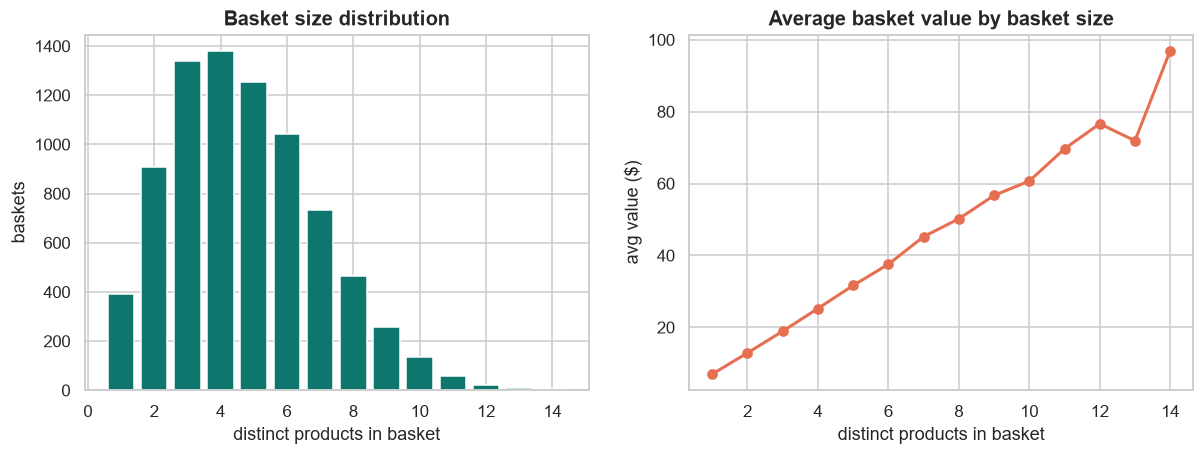

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sizes = baskets["items"].value_counts().sort_index()
axes[0].bar(sizes.index, sizes.values, color=PALETTE["primary"])
axes[0].set(title="Basket size distribution", xlabel="distinct products in basket", ylabel="baskets")
aov = baskets.groupby("items")["value"].mean()
axes[1].plot(aov.index, aov.values, marker="o", color=PALETTE["accent"], lw=2)
axes[1].set(title="Average basket value by basket size", xlabel="distinct products in basket", ylabel="avg value ($)")
fig.savefig(FIG / "01_basket_size.png"); plt.show()

Each extra product adds roughly the price of one item to the basket, so getting one more item into the typical 4–5 item basket is a direct lever on average order value.

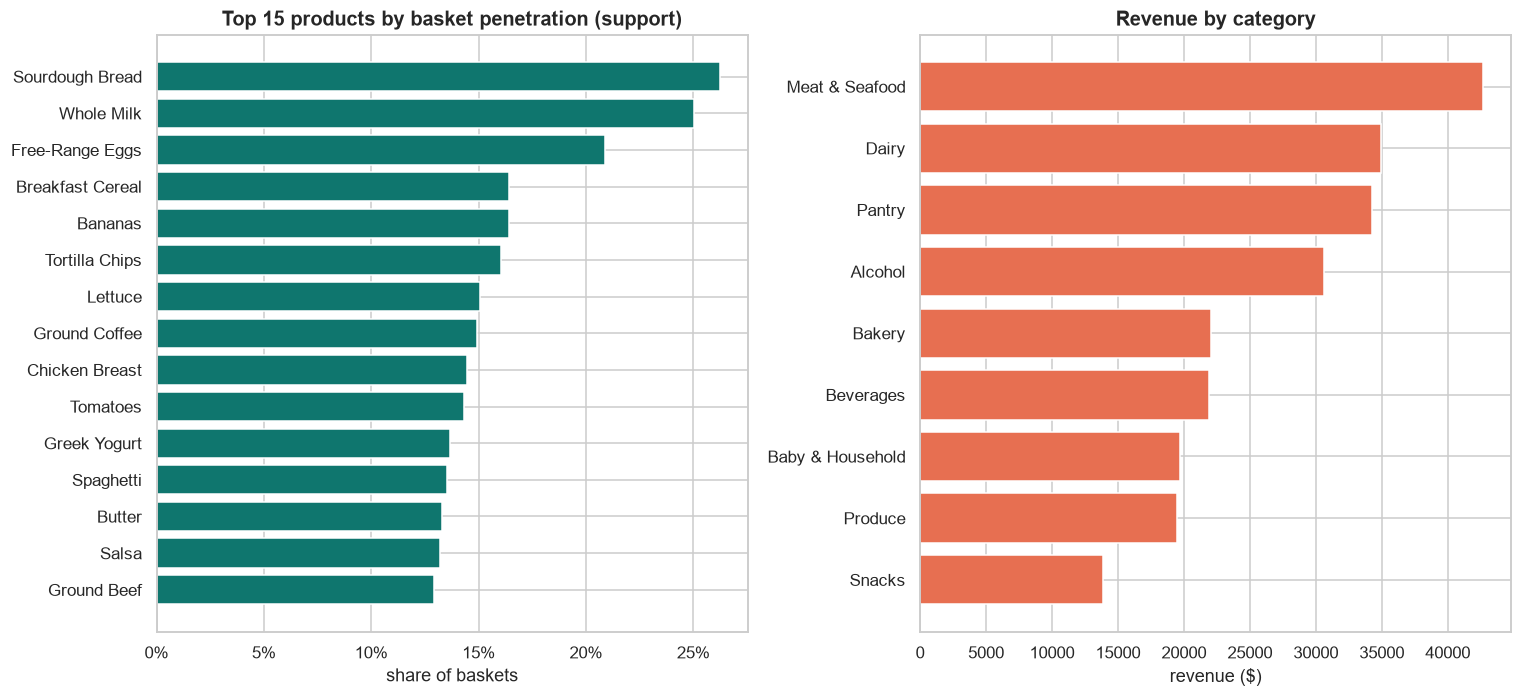

,product_name,category,baskets,revenue,support
32,Sourdough Bread,Bakery,2098,12987.45,0.262250
39,Whole Milk,Dairy,2001,4662.21,0.250125
13,Free-Range Eggs,Dairy,1671,9861.58,0.208875
3,Breakfast Cereal,Pantry,1314,8060.08,0.164250
2,Bananas,Produce,1312,2623.86,0.164000
38,Tortilla Chips,Snacks,1284,6111.56,0.160500
20,Lettuce,Produce,1204,3372.36,0.150500
17,Ground Coffee,Beverages,1195,13287.99,0.149375
7,Chicken Breast,Meat & Seafood,1157,13586.86,0.144625
37,Tomatoes,Produce,1146,4005.51,0.143250


In [9]:
prod = (clean.groupby(["product_name", "category"])
        .agg(baskets=("invoice_no", "nunique"), revenue=("line_total", "sum")).reset_index())
prod["support"] = prod["baskets"] / len(baskets)
prod = prod.sort_values("baskets", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
top = prod.head(15).iloc[::-1]
axes[0].barh(top["product_name"], top["support"], color=PALETTE["primary"])
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
axes[0].set(title="Top 15 products by basket penetration (support)", xlabel="share of baskets")
cat = clean.groupby("category")["line_total"].sum().sort_values()
axes[1].barh(cat.index, cat.values, color=PALETTE["accent"])
axes[1].set(title="Revenue by category", xlabel="revenue ($)")
fig.tight_layout(); fig.savefig(FIG / "02_top_products_categories.png"); plt.show()
prod.head(10)

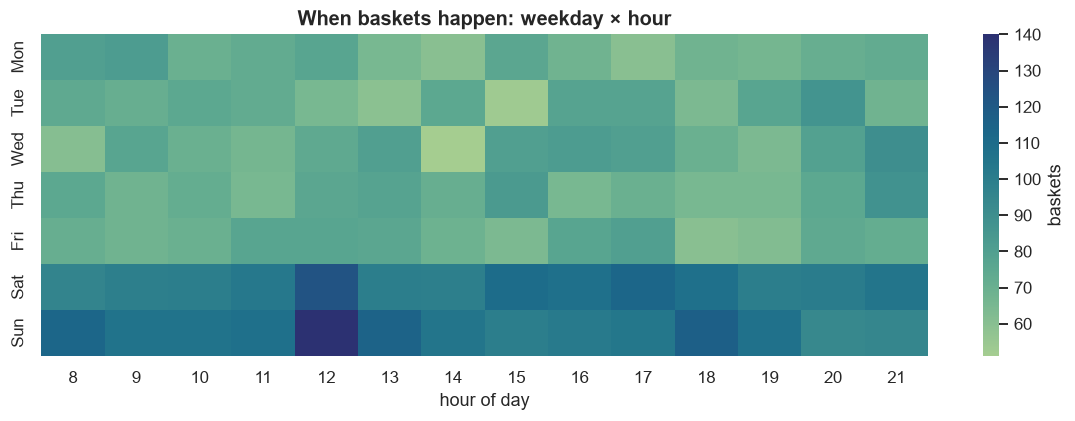

In [10]:
heat = (baskets.assign(weekday=baskets["when"].dt.day_name().str[:3], hour=baskets["when"].dt.hour)
        .pivot_table(index="weekday", columns="hour", values="items", aggfunc="size")
        .reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]))
fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(heat, cmap="crest", ax=ax, cbar_kws={"label": "baskets"})
ax.set(title="When baskets happen: weekday × hour", xlabel="hour of day", ylabel="")
fig.savefig(FIG / "03_weekday_hour_heatmap.png"); plt.show()

Weekends carry about 50% more baskets per day than weekdays, so weekend endcaps and bundle displays get the most exposure.

### SQL summaries

`scripts/run_sql.py` loads the raw CSVs into SQLite (`data/retail.db`) and saves every named query in `sql/` to `outputs/sql_results/`. Two of them are re-run here directly against the database.

In [11]:
con = sqlite3.connect(DATA / "retail.db")
pd.read_sql_query("""
    SELECT store_id, COUNT(DISTINCT invoice_no) AS transactions,
           ROUND(SUM(line_total) / COUNT(DISTINCT invoice_no), 2) AS avg_order_value
    FROM transactions GROUP BY store_id ORDER BY transactions DESC""", con)

,store_id,transactions,avg_order_value
0,S01-Downtown,3604,29.95
1,S02-Riverside,2520,29.69
2,S03-Northgate,1876,30.21


In [12]:
# category pairs that share a basket more often than chance (from sql/03_product_analysis.sql)
pd.read_csv(OUT / "sql_results" / "category_pairs.csv").head(8)

,category_a,category_b,together,support,lift
0,Alcohol,Snacks,846,0.1057,1.836
1,Alcohol,Baby & Household,285,0.0356,1.240
2,Meat & Seafood,Produce,2284,0.2855,1.184
3,Bakery,Meat & Seafood,1700,0.2125,1.138
4,Bakery,Snacks,1137,0.1421,1.116
5,Bakery,Dairy,2631,0.3289,1.100
6,Dairy,Pantry,2953,0.3691,1.074
7,Pantry,Produce,2677,0.3346,1.072


## 4. Frequent itemsets with Apriori

Each basket becomes a row of a one-hot matrix (True if the product is in it). Quantity is ignored: the question is whether products appear *together*, not how many units were bought.

**Threshold:** `min_support = 0.01`, so an itemset must appear in at least 80 of the 8,000 baskets. The sensitivity check below shows how the number of itemsets responds to this choice.

In [13]:
basket_lists = clean.groupby("invoice_no")["product_name"].apply(lambda s: sorted(set(s))).to_list()
te = TransactionEncoder()
onehot = pd.DataFrame(te.fit(basket_lists).transform(basket_lists), columns=te.columns_)
print(onehot.shape)
onehot.iloc[:5, :8]

(8000, 40)


,Avocados,Baby Wipes,Bananas,Breakfast Cereal,Burger Buns,Butter,Cheddar Cheese,Chicken Breast
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,True,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,True,False,False


In [14]:
MIN_SUPPORT = 0.01
itemsets = apriori(onehot, min_support=MIN_SUPPORT, use_colnames=True)
itemsets["length"] = itemsets["itemsets"].map(len)
itemsets["baskets"] = (itemsets["support"] * len(onehot)).round().astype(int)
print(itemsets["length"].value_counts().sort_index().rename("itemsets by size").to_string())

sens = pd.DataFrame([(s, len(apriori(onehot, min_support=s, use_colnames=True)))
                     for s in [0.005, 0.01, 0.02, 0.03, 0.05, 0.1]], columns=["min_support", "frequent_itemsets"])
sens

length
1     40
2    427
3    131
4     14
5      1


,min_support,frequent_itemsets
0,0.005,1622
1,0.010,613
2,0.020,216
3,0.030,127
4,0.050,61
5,0.100,26


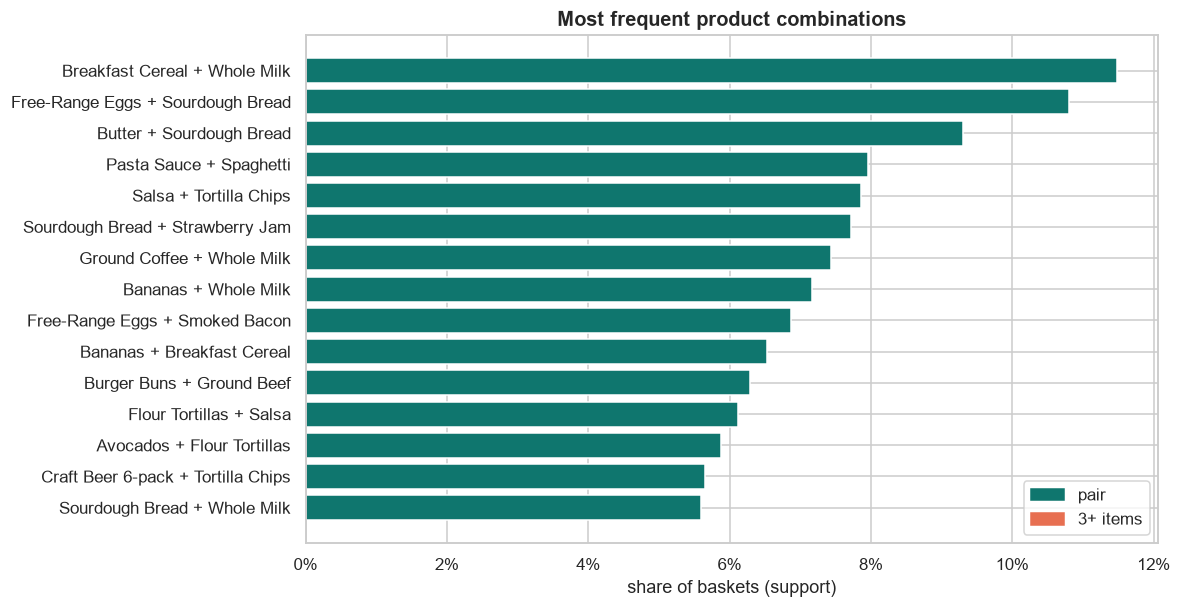

In [15]:
combos = itemsets[itemsets["length"] >= 2].sort_values("support", ascending=False).head(15).copy()
combos["label"] = combos["itemsets"].map(lambda s: " + ".join(sorted(s)))
fig, ax = plt.subplots(figsize=(10, 6))
c = combos.iloc[::-1]
ax.barh(c["label"], c["support"], color=np.where(c["length"] >= 3, PALETTE["accent"], PALETTE["primary"]))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set(title="Most frequent product combinations", xlabel="share of baskets (support)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PALETTE["primary"]), plt.Rectangle((0, 0), 1, 1, color=PALETTE["accent"])],
          labels=["pair", "3+ items"], loc="lower right")
fig.savefig(FIG / "04_frequent_combinations.png"); plt.show()

itemsets_out = itemsets.assign(itemset=itemsets["itemsets"].map(lambda s: " + ".join(sorted(s)))) \
    .sort_values(["length", "support"], ascending=[True, False])[["itemset", "length", "support", "baskets"]]
itemsets_out.to_csv(OUT / "frequent_itemsets.csv", index=False)

Raw frequency favours staples: Sourdough Bread and Whole Milk are in a quarter of all baskets, so they show up in many combinations just by being common. Lift corrects for that, which is why the rules below are ranked by lift.

## 5. Association rules

Rules are generated from the frequent itemsets and kept when **lift ≥ 1.2** (at least 20% likelier than chance) and **confidence ≥ 0.25** (at least one in four baskets with the antecedent also has the consequent). They are ranked by lift, then confidence.

In [16]:
rules = association_rules(itemsets.drop(columns=["length", "baskets"]), num_itemsets=len(onehot),
                          metric="lift", min_threshold=1.0)
fmt = lambda s: ", ".join(sorted(s))
rules = rules.assign(
    antecedents=rules["antecedents"].map(fmt), consequents=rules["consequents"].map(fmt),
    rule_size=rules["antecedents"].map(len) + rules["consequents"].map(len),
)
cols = ["antecedents", "consequents", "rule_size", "antecedent support", "consequent support",
        "support", "confidence", "lift", "leverage", "conviction"]
strong = (rules[(rules["lift"] >= 1.2) & (rules["confidence"] >= 0.25)][cols]
          .sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True))
strong.insert(0, "rank", strong.index + 1)
strong["baskets"] = (strong["support"] * len(onehot)).round().astype(int)
strong = strong.round({"antecedent support": 4, "consequent support": 4, "support": 4,
                       "confidence": 4, "lift": 3, "leverage": 4, "conviction": 3})
strong.to_csv(OUT / "association_rules.csv", index=False)
print(f"{len(rules):,} rules with lift >= 1 · {len(strong):,} kept after lift >= 1.2 and confidence >= 0.25")
strong.head(25)

1,032 rules with lift >= 1 · 594 kept after lift >= 1.2 and confidence >= 0.25


,rank,antecedents,consequents,rule_size,antecedent support,consequent support,support,confidence,lift,leverage,conviction,baskets
0,1,"Cheddar Cheese, Ground Beef, Lettuce","Burger Buns, Tomatoes",5,0.0209,0.0380,0.0110,0.5269,13.867,0.0102,2.034,88
1,2,"Burger Buns, Tomatoes","Cheddar Cheese, Ground Beef, Lettuce",5,0.0380,0.0209,0.0110,0.2895,13.867,0.0102,1.378,88
2,3,"Cheddar Cheese, Ground Beef, Tomatoes","Burger Buns, Lettuce",5,0.0226,0.0391,0.0110,0.4862,12.427,0.0101,1.870,88
3,4,"Burger Buns, Lettuce","Cheddar Cheese, Ground Beef, Tomatoes",5,0.0391,0.0226,0.0110,0.2812,12.427,0.0101,1.360,88
4,5,"Burger Buns, Cheddar Cheese, Lettuce","Ground Beef, Tomatoes",5,0.0231,0.0391,0.0110,0.4757,12.158,0.0101,1.833,88
5,6,"Ground Beef, Tomatoes","Burger Buns, Cheddar Cheese, Lettuce",5,0.0391,0.0231,0.0110,0.2812,12.158,0.0101,1.359,88
6,7,"Ground Beef, Tomatoes","Burger Buns, Lettuce",4,0.0391,0.0391,0.0179,0.4569,11.677,0.0163,1.769,143
7,8,"Burger Buns, Lettuce","Ground Beef, Tomatoes",4,0.0391,0.0391,0.0179,0.4569,11.677,0.0163,1.769,143
8,9,"Cheddar Cheese, Ground Beef","Burger Buns, Tomatoes",4,0.0470,0.0380,0.0208,0.4415,11.618,0.0190,1.722,166
9,10,"Burger Buns, Tomatoes","Cheddar Cheese, Ground Beef",4,0.0380,0.0470,0.0208,0.5461,11.618,0.0190,2.099,166


In [17]:
# one row per product pair (the direction with the higher confidence), for the headline list
pairs = strong[strong["rule_size"] == 2].copy()
pairs["pair"] = pairs.apply(lambda r: " + ".join(sorted([r["antecedents"], r["consequents"]])), axis=1)
top_pairs = pairs.sort_values("confidence", ascending=False).drop_duplicates("pair") \
                 .sort_values("lift", ascending=False).head(15)
top_pairs[["pair", "antecedents", "consequents", "support", "confidence", "lift", "baskets"]] \
    .to_csv(OUT / "top_product_pairs.csv", index=False)
top_pairs[["pair", "antecedents", "consequents", "support", "confidence", "lift", "baskets"]]

,pair,antecedents,consequents,support,confidence,lift,baskets
84,Baby Wipes + Diapers,Baby Wipes,Diapers,0.0545,0.6976,7.961,436
160,Avocados + Flour Tortillas,Avocados,Flour Tortillas,0.0588,0.5774,5.668,470
180,Parmesan + Pasta Sauce,Parmesan,Pasta Sauce,0.0428,0.6075,5.352,342
183,Burger Buns + Ground Beef,Burger Buns,Ground Beef,0.0629,0.6853,5.312,503
190,Pasta Sauce + Spaghetti,Pasta Sauce,Spaghetti,0.0796,0.7015,5.182,637
198,Parmesan + Spaghetti,Parmesan,Spaghetti,0.0485,0.6892,5.091,388
236,Green Tea + Honey,Honey,Green Tea,0.0366,0.4302,4.583,293
243,Flour Tortillas + Salsa,Flour Tortillas,Salsa,0.0611,0.6000,4.545,489
248,Lemons + Salmon Fillet,Salmon Fillet,Lemons,0.0515,0.5302,4.396,412
261,Burger Buns + Cheddar Cheese,Burger Buns,Cheddar Cheese,0.0465,0.5068,4.141,372


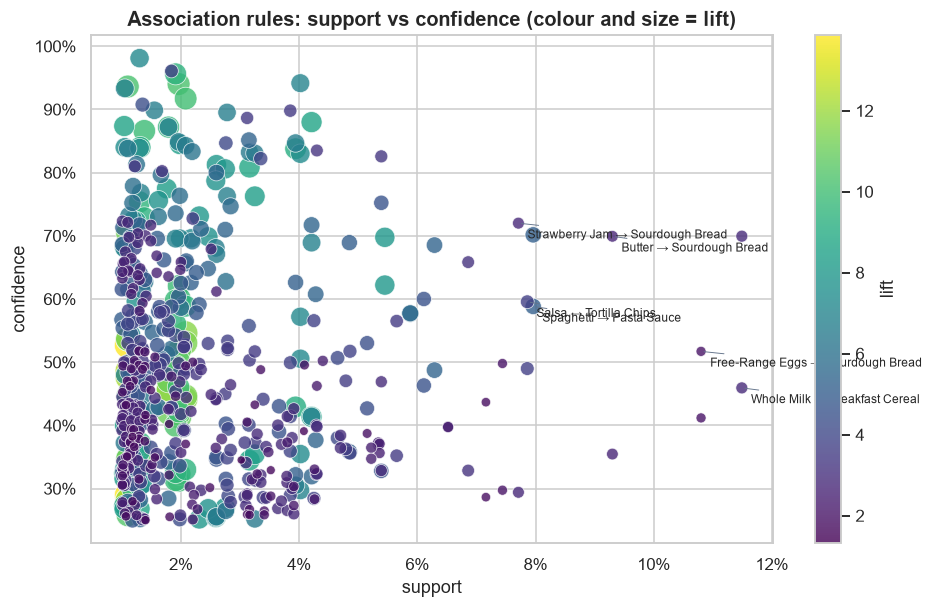

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))
pts = ax.scatter(strong["support"], strong["confidence"], c=strong["lift"], s=strong["lift"] * 22,
                 cmap="viridis", alpha=.8, edgecolor="white", lw=.5)
# label the six highest-support pair rules among the strong ones
for _, r in pairs.sort_values("support", ascending=False).drop_duplicates("pair").head(6).iterrows():
    ax.annotate(f"{r['antecedents']} → {r['consequents']}", (r["support"], r["confidence"]),
                fontsize=8, xytext=(6, -10), textcoords="offset points",
                arrowprops=dict(arrowstyle="-", color="#64748B", lw=.6))
fig.colorbar(pts, label="lift")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set(title="Association rules: support vs confidence (colour and size = lift)", xlabel="support", ylabel="confidence")
fig.savefig(FIG / "05_rules_scatter.png"); plt.show()

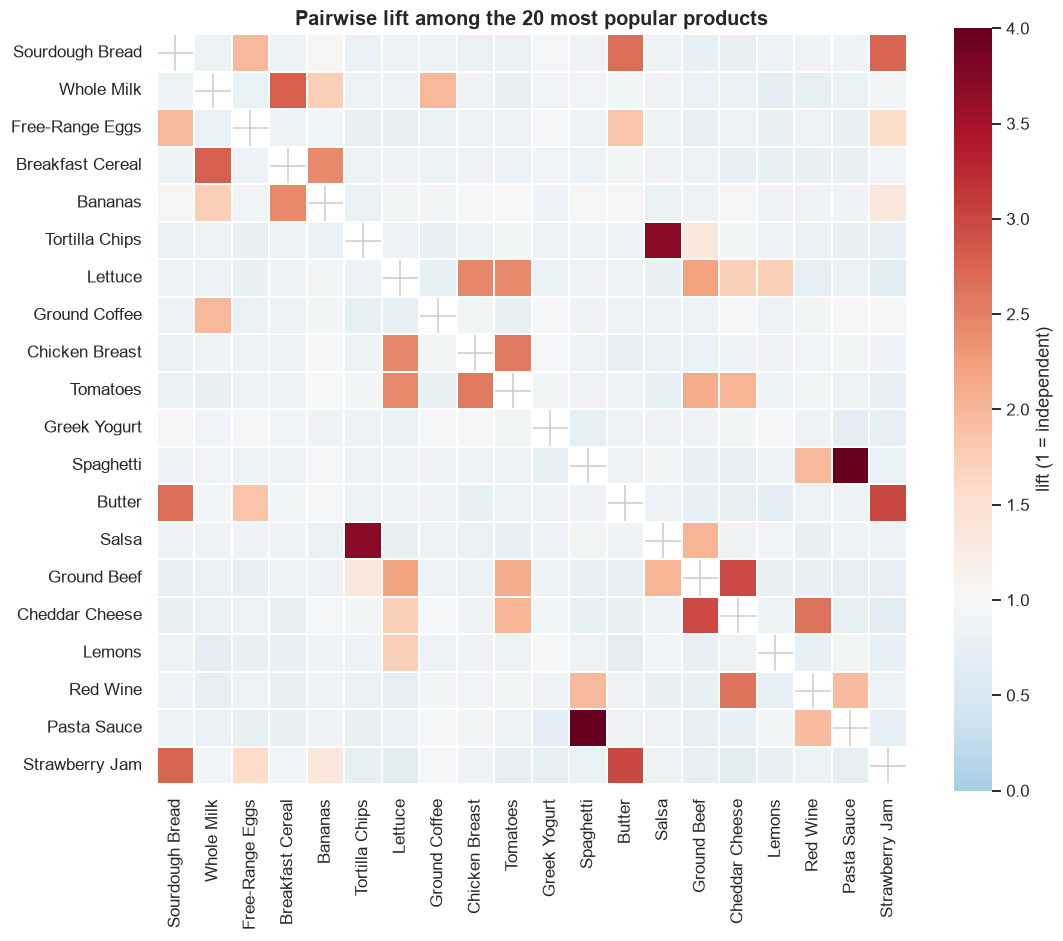

In [19]:
top_names = prod.head(20)["product_name"].to_list()
p = onehot[top_names].astype(int)
co = p.T @ p
supp = np.diag(co) / len(p)
lift_mat = ((co / len(p)) / np.outer(supp, supp)).mask(np.eye(len(top_names), dtype=bool))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(lift_mat, cmap="RdBu_r", center=1, vmin=0, vmax=4, ax=ax, square=True,
            cbar_kws={"label": "lift (1 = independent)"}, linewidths=.3)
ax.set_title("Pairwise lift among the 20 most popular products")
fig.savefig(FIG / "06_pair_lift_heatmap.png"); plt.show()

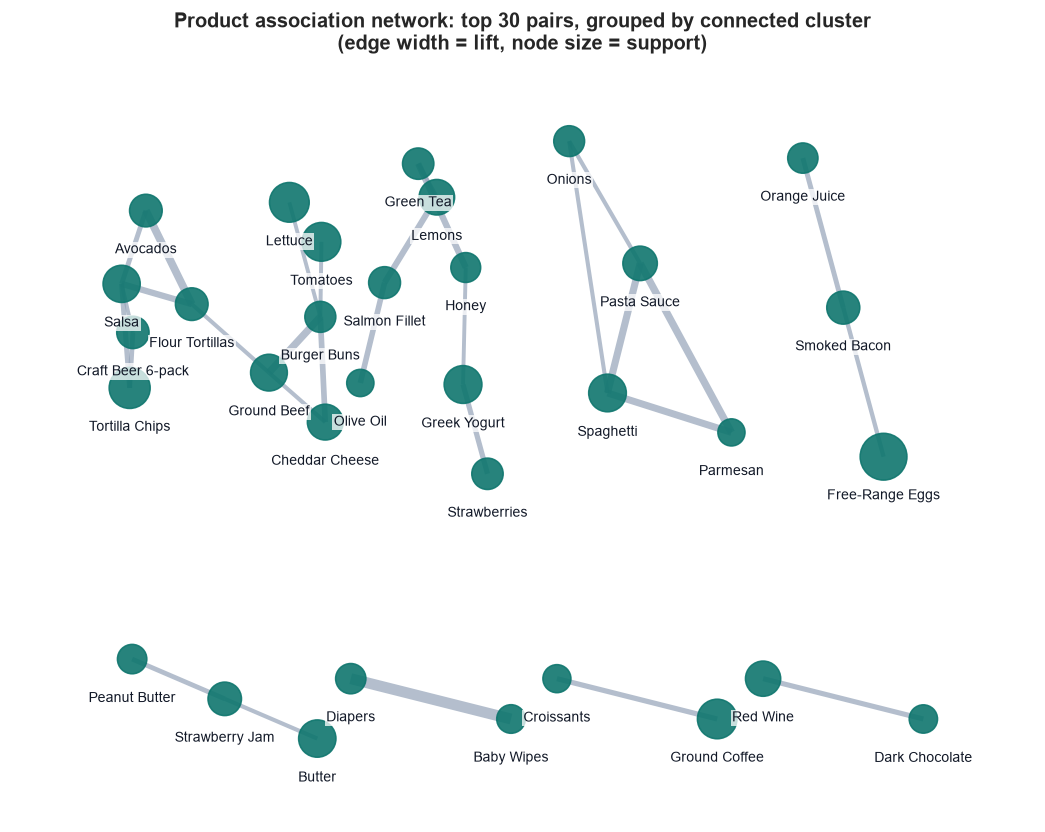

In [20]:
net = pairs.drop_duplicates("pair").sort_values("lift", ascending=False).head(30)
G = nx.Graph()
for _, r in net.iterrows():
    G.add_edge(r["antecedents"], r["consequents"], lift=r["lift"])
supp_map = prod.set_index("product_name")["support"]
# lay out each connected group (a shopping mission) on its own, then arrange the groups on a grid
pos, groups = {}, sorted(nx.connected_components(G), key=len, reverse=True)
for i, nodes in enumerate(groups):
    sub = nx.spring_layout(G.subgraph(nodes), seed=7, k=1.2, scale=.38 * min(1, len(nodes) / 4) ** .5 + .12)
    gx, gy = i % 4, -(i // 4)
    pos.update({n: (x + gx, y * .85 + gy) for n, (x, y) in sub.items()})
fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx_edges(G, pos, ax=ax, width=[G[u][v]["lift"] * .9 for u, v in G.edges()],
                       edge_color=PALETTE["muted"], alpha=.7)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[supp_map[n] * 4500 for n in G.nodes()],
                       node_color=PALETTE["primary"], alpha=.9)
nx.draw_networkx_labels(G, {n: (x, y - .1) for n, (x, y) in pos.items()}, ax=ax, font_size=9,
                        font_color="#111827", bbox=dict(fc="white", ec="none", alpha=.75, pad=1))
ax.set_title("Product association network: top 30 pairs, grouped by connected cluster\n(edge width = lift, node size = support)")
ax.margins(.08)
ax.axis("off"); fig.savefig(FIG / "07_association_network.png"); plt.show()

## 6. Cross-check against SQL

In [21]:
sql_pairs = pd.read_csv(OUT / "sql_results" / "product_pair_rules.csv")
check = pairs.merge(sql_pairs, left_on=["antecedents", "consequents"], right_on=["antecedent", "consequent"], suffixes=("", "_sql"))
diff = (check[["support", "confidence", "lift"]].values - check[["support_sql", "confidence_sql", "lift_sql"]].values)
print(f"{len(check)} of {len(pairs)} pair rules matched in SQL output · max abs difference: {np.abs(diff).max():.4f}")

109 of 109 pair rules matched in SQL output · max abs difference: 0.0001


## 7. From rules to recommendations

A simple recommender: given what is already in the basket, score every product not in it by the best rule whose antecedent is fully contained in the basket. That is the logic a "frequently bought together" widget or a checkout prompt would use.

In [22]:
rule_sets = strong.assign(a=strong["antecedents"].str.split(", ").map(frozenset))

def recommend(basket, k=3):
    basket = frozenset(basket)
    hits = rule_sets[rule_sets["a"] <= basket]
    hits = hits[~hits["consequents"].str.split(", ").map(lambda c: bool(set(c) & basket))]
    return (hits.sort_values(["lift", "confidence"], ascending=False)
                .drop_duplicates("consequents").head(k)[["antecedents", "consequents", "confidence", "lift"]])

for b in [["Spaghetti"], ["Flour Tortillas", "Salsa"], ["Diapers"], ["Ground Coffee"], ["Burger Buns"]]:
    print("Basket:", b)
    print(recommend(b).to_string(index=False), "\n")

Basket: ['Spaghetti']
antecedents           consequents  confidence  lift
  Spaghetti Parmesan, Pasta Sauce      0.2973 6.955
  Spaghetti           Pasta Sauce      0.5882 5.182
  Spaghetti              Parmesan      0.3583 5.091 

Basket: ['Flour Tortillas', 'Salsa']
           antecedents              consequents  confidence  lift
Flour Tortillas, Salsa Avocados, Tortilla Chips      0.3231 9.828
Flour Tortillas, Salsa    Avocados, Ground Beef      0.3129 9.778
Flour Tortillas, Salsa                 Avocados      0.6892 6.773 

Basket: ['Diapers']
antecedents consequents  confidence  lift
    Diapers  Baby Wipes       0.622 7.961 

Basket: ['Ground Coffee']
  antecedents consequents  confidence  lift
Ground Coffee  Croissants      0.2845 3.787
Ground Coffee  Whole Milk      0.4979 1.991 

Basket: ['Burger Buns']
antecedents                 consequents  confidence  lift
Burger Buns Cheddar Cheese, Ground Beef      0.4292 9.131
Burger Buns       Ground Beef, Tomatoes      0.3447 8.810
B

In [23]:
sizes_df = strong["rule_size"].value_counts().sort_index()
print("rules by size:", sizes_df.to_dict())
print("median lift of kept rules:", strong["lift"].median().round(2))
by_ante = strong[strong["rule_size"] == 2].groupby("antecedents").size().sort_values(ascending=False).head(8)
print("products that trigger the most rules:\n", by_ante.to_string())

rules by size: {2: 109, 3: 342, 4: 122, 5: 21}
median lift of kept rules: 3.75
products that trigger the most rules:
 antecedents
Ground Beef       6
Cheddar Cheese    5
Salsa             5
Olive Oil         5
Avocados          4
Burger Buns       4
Lettuce           4
Strawberry Jam    4


## 8. Findings and business applications

**The strongest associations are meal and mission kits.** The top pairs by lift are things that are cooked or used together:

| Pair | Confidence | Lift | Baskets |
|---|---|---|---|
| Baby Wipes → Diapers | 69.8% | 7.96 | 436 |
| Avocados → Flour Tortillas | 57.7% | 5.67 | 470 |
| Parmesan → Pasta Sauce | 60.8% | 5.35 | 342 |
| Burger Buns → Ground Beef | 68.5% | 5.31 | 503 |
| Pasta Sauce → Spaghetti | 70.2% | 5.18 | 637 |
| Salmon Fillet → Lemons | 53.0% | 4.40 | 412 |
| Croissants → Ground Coffee | 56.6% | 3.79 | 340 |

**Three-item rules are sharper still.** 88% of baskets with Avocados and Salsa also contain Flour Tortillas (lift 8.6), and 84% of baskets with Cheddar Cheese and Ground Beef contain Burger Buns (lift 9.1). Once two parts of a kit are in the basket, the third is close to certain, which makes these the best triggers for a "complete your meal" prompt.

**High-traffic staples are weak recommendation targets.** Breakfast Cereal → Whole Milk has 70% confidence but a lift of only 2.8, because milk is already in a quarter of all baskets. Recommending milk mostly tells people what they were going to buy anyway. Lift picks out the suggestions that change behaviour.

**The classic Diapers → Beer link appears, but it is modest.** 21.5% of diaper baskets include a craft-beer six-pack (lift 2.15). That is real and worth a test, but it is far weaker than Diapers ↔ Baby Wipes.

### How to use these rules

- **Product placement.** Place pairs with high lift but different store sections next to each other: Salsa and Avocados beside the tortillas, Parmesan on the pasta aisle, Lemons at the fish counter, Croissants beside the coffee. Keep the very strong pairs (Diapers and Wipes) in the same bay so the second item is never missed.
- **Bundles.** Price kits around the 3-item rules: a *Taco Night* kit (Tortillas + Salsa + Avocados), *Burger Night* (Buns + Beef + Cheddar), *Pasta Night* (Spaghetti + Sauce + Parmesan) and a *Baby Essentials* pack. Discount the lower-margin item, not the anchor.
- **Cross-selling campaigns.** Use `recommend()` for checkout prompts and "frequently bought together" on the app: trigger on the antecedent and show the highest-lift consequent not already in the basket. Coupons work best on rules with high lift but moderate confidence (Spaghetti → Parmesan at 36%), where there is room to grow conversion.
- **Measure it.** Each campaign should be an A/B test with average order value and attach rate (share of trigger baskets that add the recommended item) as the metrics. Association rules show co-occurrence, not cause.